# Data Cleaning and Pre-processing
**Yanyi (Elaine) Chen**

We prepare the CDC 2022 BRFSS data to study how demographic, socioeconomic,
household, and lifestyle characteristics are associated with sleep duration.

**Colab setup:** Open this notebook from the team Drive's Data_Cleaning
folder and run all cells. When prompted, connect your Google Drive account.
The notebook reads the original ZIP and saves the full cleaned CSV plus
three unencoded training/validation/test CSVs in that shared folder. For local use, keep this notebook and LLCP2022XPT.zip together.


## 1. Load the data and select columns

The publicly available [CDC 2022 BRFSS dataset](https://www.cdc.gov/brfss/annual_data/annual_2022.html)
contains **445,132 respondents**. Our raw XPT has **328 columns**.
We retain 14 columns related to the topic or needed for survey analysis:

| Original column | Clean column | Meaning |
|---|---|---|
| SLEPTIM1 | sleep_hours | Average sleep hours per 24-hour period |
| _AGEG5YR | age_group | Age interval |
| SEXVAR | sex | Respondent sex |
| INCOME3 | income_group | Annual household income interval |
| EDUCA | education_level | Highest education completed |
| EMPLOY1 | employment_status | Current employment status |
| MARITAL | marital_status | Marital/partner status |
| CHILDREN | children_group | Household children under 18 |
| EXERANY2 | physical_activity | Any leisure-time physical activity in the past month |
| _SMOKER3 | smoking_status | Current or past smoking status |
| _STATE | state | State or District of Columbia |
| _LLCPWT | survey_weight | Original final survey weight |
| _STSTR | stratum_id | Original sampling-stratum ID |
| _PSU | psu_id | Original primary-sampling-unit ID |

The ten personal/geographic characteristics describe groups whose sleep may
differ. SLEPTIM1 is used to create enough_sleep. The last three fields already
exist in the CDC data and are retained for weighted survey analysis.


In [1]:
from pathlib import Path
import shutil
import zipfile
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

# In Colab, connect to the team's shared Drive. Locally, use this folder.
PROJECT_DIR = Path.cwd()
try:
    from google.colab import drive
except ImportError:
    pass
else:
    drive.mount("/content/drive")
    PROJECT_DIR = Path(
        "/content/drive/Shareddrives/CIS5450 Final Project/Data_Cleaning"
    )

# Keep the large extracted XPT in Colab's temporary storage, not shared Drive.
INPUT_FILE = (Path("/content/LLCP2022.XPT") if Path("/content").is_dir()
              else PROJECT_DIR / "LLCP2022.XPT")
ZIP_FILE = PROJECT_DIR / "LLCP2022XPT.zip"
OUTPUT_DIR = PROJECT_DIR

# If needed, extract the uploaded ZIP into a consistently named XPT.
if not INPUT_FILE.exists():
    with zipfile.ZipFile(ZIP_FILE) as archive:
        name = next(n for n in archive.namelist()
                    if n.strip().lower().endswith(".xpt"))
        with archive.open(name) as source, INPUT_FILE.open("wb") as dest:
            shutil.copyfileobj(source, dest)

columns = [
    "SLEPTIM1", "_AGEG5YR", "SEXVAR", "INCOME3", "EDUCA",
    "EMPLOY1", "MARITAL", "CHILDREN", "EXERANY2", "_SMOKER3",
    "_STATE", "_LLCPWT", "_STSTR", "_PSU",
]

# Read in chunks because the original XPT is large.
reader = pd.read_sas(INPUT_FILE, format="xport", encoding="utf-8", chunksize=20000)
chunks = []
try:
    for chunk in reader:
        raw_column_count = chunk.shape[1]
        chunks.append(chunk[columns].copy())
finally:
    reader.close()

df = pd.concat(chunks, ignore_index=True).apply(pd.to_numeric, errors="coerce")
del chunks
raw_rows = len(df)
row_counts = [("Raw data", raw_rows)]

print(f"Raw data: {raw_rows:,} rows, {raw_column_count} columns")
print(f"Selected data: {len(df):,} rows, {df.shape[1]} columns")


Mounted at /content/drive
Raw data: 445,132 rows, 328 columns
Selected data: 445,132 rows, 14 columns


**Result:** We selected **14 of the 328 original columns** and retained all
**445,132 rows** at this step.


## 2. Filter the study population and inspect unusual values

We keep the **50 US states and DC**, excluding territories. Valid sleep
responses are whole hours from **1 to 24**; 77, 99, missing, and other invalid
sleep responses are excluded. We also check for positive finite weights and
valid integer survey-design IDs. **EDA supporting cleaning:** Before deciding how to handle unusual values,
we inspect valid sleep durations and the number of children in larger households.


In [2]:
# FIPS code -> postal abbreviation; comments give each state's full name.
state_abbreviations = {
    1: "AL",   # Alabama
    2: "AK",   # Alaska
    4: "AZ",   # Arizona
    5: "AR",   # Arkansas
    6: "CA",   # California
    8: "CO",   # Colorado
    9: "CT",   # Connecticut
    10: "DE",  # Delaware
    11: "DC",  # District of Columbia
    12: "FL",  # Florida
    13: "GA",  # Georgia
    15: "HI",  # Hawaii
    16: "ID",  # Idaho
    17: "IL",  # Illinois
    18: "IN",  # Indiana
    19: "IA",  # Iowa
    20: "KS",  # Kansas
    21: "KY",  # Kentucky
    22: "LA",  # Louisiana
    23: "ME",  # Maine
    24: "MD",  # Maryland
    25: "MA",  # Massachusetts
    26: "MI",  # Michigan
    27: "MN",  # Minnesota
    28: "MS",  # Mississippi
    29: "MO",  # Missouri
    30: "MT",  # Montana
    31: "NE",  # Nebraska
    32: "NV",  # Nevada
    33: "NH",  # New Hampshire
    34: "NJ",  # New Jersey
    35: "NM",  # New Mexico
    36: "NY",  # New York
    37: "NC",  # North Carolina
    38: "ND",  # North Dakota
    39: "OH",  # Ohio
    40: "OK",  # Oklahoma
    41: "OR",  # Oregon
    42: "PA",  # Pennsylvania
    44: "RI",  # Rhode Island
    45: "SC",  # South Carolina
    46: "SD",  # South Dakota
    47: "TN",  # Tennessee
    48: "TX",  # Texas
    49: "UT",  # Utah
    50: "VT",  # Vermont
    51: "VA",  # Virginia
    53: "WA",  # Washington
    54: "WV",  # West Virginia
    55: "WI",  # Wisconsin
    56: "WY",  # Wyoming
}

df = df.loc[df["_STATE"].isin(state_abbreviations)].copy()
row_counts.append(("Keep 50 states and DC", len(df)))

df = df.loc[df["SLEPTIM1"].isin(range(1, 25))].copy()
row_counts.append(("Keep valid sleep responses", len(df)))

valid_design = (
    df["_LLCPWT"].gt(0) & df["_LLCPWT"].lt(float("inf"))
    & df["_STSTR"].between(1, 2**53 - 1) & df["_PSU"].between(1, 2**53 - 1)
    & df["_STSTR"].mod(1).eq(0) & df["_PSU"].mod(1).eq(0)
)
df = df.loc[valid_design].copy()
row_counts.append(("Keep valid weights and design IDs", len(df)))

row_summary = pd.DataFrame(row_counts, columns=["step", "rows_remaining"])
row_summary["rows_removed"] = (
    -row_summary["rows_remaining"].diff()
).fillna(0).astype(int)
display(row_summary)

# Inspect the observed distributions before choosing outlier/grouping rules.
display(df["SLEPTIM1"].value_counts().sort_index().rename_axis(
    "sleep_hours"
).reset_index(name="respondents"))
children_distribution = pd.DataFrame({
    "household_children": ["0 (raw 88)", "1", "2", "3", "4+"],
    "respondents": [
        df["CHILDREN"].eq(88).sum(), df["CHILDREN"].eq(1).sum(),
        df["CHILDREN"].eq(2).sum(), df["CHILDREN"].eq(3).sum(),
        df["CHILDREN"].between(4, 87).sum(),
    ],
})
display(children_distribution)


,step,rows_remaining,rows_removed
0,Raw data,445132,0
1,Keep 50 states and DC,435826,9306
2,Keep valid sleep responses,430578,5248
3,Keep valid weights and design IDs,430578,0


,sleep_hours,respondents
0,1.0,1126
1,2.0,1510
2,3.0,3165
3,4.0,12048
4,5.0,29196
5,6.0,93620
6,7.0,130713
7,8.0,122881
8,9.0,20932
9,10.0,10273


,household_children,respondents
0,0 (raw 88),311162
1,1,44659
2,2,36847
3,3,15601
4,4+,8375


**Result:** Excluding territories removes **9,306 rows**. Invalid sleep
responses account for another **5,248 rows**. No additional rows have invalid
weights or design IDs, leaving **430,578 respondents**.

**Outlier decision:** Valid durations range from 1 to 24 hours; 1,519
respondents report more than 12 hours. These are unusual but valid CDC responses,
so we retain them instead of trimming by an arbitrary IQR rule. Categorical
codes are not continuous quantities, and survey weights are not winsorized.


## 3. Clean categories, standardize names, and create enough_sleep

We keep valid CDC codes and convert invalid or missing categorical answers
to **Unknown**. CHILDREN=88 means no children and becomes 0; positive counts
are grouped into 1, 2, and 3+. State codes become postal abbreviations, and
smoking codes become English labels. The distribution above shows only
**8,375** households with four or more children, compared with **311,162**
with none. Grouping three or more children provides a simpler representation
of the sparse upper tail without removing respondents.

**Category meanings after cleaning:**

| Column | Value meanings |
|---|---|
| age_group | 1=18-24; 2=25-29; 3=30-34; 4=35-39; 5=40-44; 6=45-49; 7=50-54; 8=55-59; 9=60-64; 10=65-69; 11=70-74; 12=75-79; 13=80+ |
| sex | 1=Male; 2=Female |
| income_group | Annual household income in USD: 1=below 10,000; 2=10,000 to below 15,000; 3=15,000 to below 20,000; 4=20,000 to below 25,000; 5=25,000 to below 35,000; 6=35,000 to below 50,000; 7=50,000 to below 75,000; 8=75,000 to below 100,000; 9=100,000 to below 150,000; 10=150,000 to below 200,000; 11=200,000+ |
| education_level | 1=No school/kindergarten only; 2=Grades 1-8; 3=Grades 9-11; 4=Grade 12/GED; 5=College 1-3 years/some college or technical school; 6=College 4+ years/college graduate |
| employment_status | 1=Employed for wages; 2=Self-employed; 3=Out of work for 1+ years; 4=Out of work for less than 1 year; 5=Homemaker; 6=Student; 7=Retired; 8=Unable to work |
| marital_status | 1=Married; 2=Divorced; 3=Widowed; 4=Separated; 5=Never married; 6=Member of an unmarried couple |
| children_group | Household children under 18: 0=None; 1=One; 2=Two; 3+=Three or more |
| physical_activity | Any leisure-time activity in the past month, excluding regular job duties: 1=Yes; 2=No |
| smoking_status | daily=Currently every day; sometimes=Currently some days; former=Previously smoked, not currently; never=Fewer than 100 lifetime cigarettes |
| state | Postal abbreviation, such as CA=California or PA=Pennsylvania; full mapping is in the previous code cell |
| enough_sleep | 1=7-24 hours (not short sleep); 0=1-6 hours (short sleep) |

Age and income values are **group codes**, not exact ages or incomes. For
smoking, daily/sometimes/former follow CDC's threshold of at least 100 lifetime
cigarettes. sleep_hours remains the actual reported hours.

### Outcome definition and justification

We define **enough_sleep = 1 for reported sleep of at least 7 hours** and
**0 for less than 7 hours**, after restricting responses to valid 1-24 hours.
This uses the CDC BRFSS short-sleep threshold with the opposite class coding:
our positive class is **not short sleep**, and the implied short_sleep indicator
would be 1 - enough_sleep. We export only enough_sleep, not both indicators.

The [CDC Chronic Disease Indicators definition](https://www.cdc.gov/cdi/indicator-definitions/sleep.html)
identifies adult short sleep as less than 7 hours per 24-hour period and uses
respondents reporting 1-24 hours as the denominator. The
[AASM/Sleep Research Society consensus (Watson et al., 2015)](https://doi.org/10.5665/sleep.4716)
also supports a 7-hour minimum for adults aged 18-60.

This outcome measures whether the **minimum duration threshold** is met. It
does not measure sleep quality, diagnose healthy sleep, or imply that very long
sleep is optimal. We do not impose a universal upper bound because this project
focuses on short sleep; age-specific recommendations and sleep quality remain
limitations. The threshold comes from published definitions, not EDA or model
performance.


In [3]:
# Use each column's own valid codes: income 7/9 and employment 7 are valid.
valid_codes = {
    "_AGEG5YR": range(1, 14), "SEXVAR": [1, 2], "INCOME3": range(1, 12),
    "EDUCA": range(1, 7), "EMPLOY1": range(1, 9), "MARITAL": range(1, 7),
    "EXERANY2": [1, 2], "_SMOKER3": range(1, 5),
}
for column, codes in valid_codes.items():
    df[column] = (
        df[column].where(df[column].isin(codes))
        .astype("Int64").astype("string").fillna("Unknown")
    )

# Convert smoking codes to readable labels; retain Unknown.
df["_SMOKER3"] = df["_SMOKER3"].map({
    "1": "daily", "2": "sometimes", "3": "former", "4": "never",
}).fillna("Unknown")

# Raw CHILDREN 88 = none; 99 = refused. Raw 0 is undefined in the codebook.
children = df["CHILDREN"].where(df["CHILDREN"].isin(range(1, 89))).replace(88, 0)
df["CHILDREN"] = (
    children.clip(upper=3).astype("Int64").astype("string")
    .replace("3", "3+").fillna("Unknown")
)

# Keep sleep hours and design IDs as integers; preserve weight precision.
for column in ["SLEPTIM1", "_STSTR", "_PSU"]:
    df[column] = df[column].astype("int64")
df["_STATE"] = df["_STATE"].map(state_abbreviations)

# Classify valid responses using the CDC short-sleep threshold (opposite coding).
df["enough_sleep"] = df["SLEPTIM1"].ge(7).astype("int8")

df = df.rename(columns={
    "SLEPTIM1": "sleep_hours", "_AGEG5YR": "age_group", "SEXVAR": "sex",
    "INCOME3": "income_group", "EDUCA": "education_level",
    "EMPLOY1": "employment_status", "MARITAL": "marital_status",
    "CHILDREN": "children_group", "EXERANY2": "physical_activity",
    "_SMOKER3": "smoking_status", "_STATE": "state",
    "_LLCPWT": "survey_weight", "_STSTR": "stratum_id", "_PSU": "psu_id",
}).reset_index(drop=True)

category_columns = [
    "age_group", "sex", "income_group", "education_level", "employment_status",
    "marital_status", "children_group", "physical_activity", "smoking_status",
    "state",
]
df[category_columns] = df[category_columns].astype("string")
print(f"After category cleaning: {df.shape[0]:,} rows, {df.shape[1]} columns")


After category cleaning: 430,578 rows, 15 columns


**Result:** Standardizing categories removes no rows. The data have
**430,578 rows and 15 columns**: 14 retained original fields and the new
enough_sleep column.


## 4. EDA supporting cleaning: missing information and Unknown

Unknown means an invalid, refused, unknown, or missing categorical response;
it does not mean zero or the absence of a behavior. We first inspect the
Unknown percentages. Because education and physical activity have low missing
rates and removing these records causes a small sample loss, we remove rows
where either education_level or physical_activity is Unknown. Unknown values
in the other categorical inputs remain explicit categories.


In [4]:
import numpy as np

# Inspect missing-information rates before choosing which rows to remove.
unknown_summary = pd.DataFrame({
    "column": category_columns,
    "unknown_count": df[category_columns].eq("Unknown").sum().to_numpy(),
    "unknown_percent":
        df[category_columns].eq("Unknown").mean().mul(100).round(2).to_numpy(),
})
display(unknown_summary.loc[unknown_summary["unknown_count"].gt(0)])

# Save the original seed-42 group assignment before dropping rows, so retained
# respondents stay in the same train/validation/test partition as before.
original_group_id = df["state"] + "_" + df["psu_id"].astype(str)
split_group_order = np.random.default_rng(42).permutation(original_group_id.unique())

# Remove low-missingness rows only; keep Unknown in all other inputs.
rows_before = len(df)
low_missing_columns = ["education_level", "physical_activity"]
unknown_flags = df[low_missing_columns].eq("Unknown")
remove_rows = unknown_flags.any(axis=1)
display(pd.DataFrame({
    "check": ["Unknown education", "Unknown physical activity", "Unknown in both", "Unique rows removed"],
    "respondents": [
        unknown_flags["education_level"].sum(),
        unknown_flags["physical_activity"].sum(),
        unknown_flags.all(axis=1).sum(), remove_rows.sum(),
    ],
}))
df = df.loc[~remove_rows].copy().reset_index(drop=True)
row_counts.append(("Remove Unknown education or physical activity", len(df)))
row_summary = pd.DataFrame(row_counts, columns=["step", "rows_remaining"])
row_summary["rows_removed"] = (-row_summary["rows_remaining"].diff()).fillna(0).astype(int)
display(row_summary)
print(f"Removed {rows_before - len(df):,} rows ({(rows_before - len(df)) / rows_before:.2%}).")
print(f"Remaining: {len(df):,} rows and {df.shape[1]} columns.")
assert not df[low_missing_columns].eq("Unknown").any().any()
print("Remaining empty cells:", int(df.isna().sum().sum()))


,column,unknown_count,unknown_percent
0,age_group,8546,1.98
2,income_group,91798,21.32
3,education_level,2114,0.49
4,employment_status,10686,2.48
5,marital_status,4473,1.04
6,children_group,13934,3.24
7,physical_activity,937,0.22
8,smoking_status,34303,7.97


,check,respondents
0,Unknown education,2114
1,Unknown physical activity,937
2,Unknown in both,46
3,Unique rows removed,3005


,step,rows_remaining,rows_removed
0,Raw data,445132,0
1,Keep 50 states and DC,435826,9306
2,Keep valid sleep responses,430578,5248
3,Keep valid weights and design IDs,430578,0
4,Remove Unknown education or physical activity,427573,3005


Removed 3,005 rows (0.70%).
Remaining: 427,573 rows and 15 columns.
Remaining empty cells: 0


**Decision and result:** Before this removal, education has **2,114 Unknown
responses (0.49%)** and physical activity has **937 (0.22%)**. The **46**
respondents missing both are counted once, so we remove **3,005 unique rows
(0.70%)**, leaving **427,573 rows**. The sample remains well above 50,000.

Income (21.32%) and smoking (7.97%) have much more missing information before
this step. We retain Unknown for these and the other categorical inputs to
avoid broader sample loss; no mean/mode values are guessed. The small sample
loss motivates this limited removal, but does not establish that missingness
is random or that deletion eliminates bias. Remaining Unknown percentages are
reported again in the training-set EDA below.


## 5. Check and export the cleaned data

We verify the 50,000-row minimum, confirm the sleep indicator matches its
definition, and export the cleaned table. The dataset remains unencoded for
the group's later analysis.


In [5]:
assert len(df) >= 50000, "The cleaned data must have at least 50,000 rows."
assert df.shape[1] == 15 and df.columns.is_unique
assert df["sleep_hours"].isin(range(1, 25)).all()
assert df["enough_sleep"].eq(df["sleep_hours"].ge(7).astype(int)).all()
assert not df.isna().any().any()

df_clean = df.copy()
output_file = OUTPUT_DIR / "brfss_2022_clean.csv"
df_clean.to_csv(output_file, index=False, encoding="utf-8")

print(f"Before cleaning: {raw_rows:,} rows, {raw_column_count} columns")
print(f"After cleaning: {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns")
print("Final columns:", ", ".join(df_clean.columns))
print("\nSleep indicator counts:")
print(df_clean["enough_sleep"].value_counts().sort_index())
print(f"\nSaved to: {output_file}")
display(df_clean.head())


Before cleaning: 445,132 rows, 328 columns
After cleaning: 427,573 rows, 15 columns
Final columns: sleep_hours, age_group, sex, income_group, education_level, employment_status, marital_status, children_group, physical_activity, smoking_status, state, survey_weight, stratum_id, psu_id, enough_sleep

Sleep indicator counts:
enough_sleep
0    139673
1    287900
Name: count, dtype: int64

Saved to: /content/drive/Shareddrives/CIS5450 Final Project/Data_Cleaning/brfss_2022_clean.csv


,sleep_hours,age_group,sex,income_group,education_level,employment_status,marital_status,children_group,physical_activity,smoking_status,state,survey_weight,stratum_id,psu_id,enough_sleep
0,8,13,2,Unknown,6,7,1,0,2,never,AL,487.612985,11011,2022000001,1
1,6,13,2,5,4,2,3,0,2,never,AL,432.100273,11011,2022000002,0
2,5,8,2,10,6,7,1,0,1,never,AL,366.743194,11011,2022000003,0
3,7,Unknown,2,Unknown,4,7,1,0,1,sometimes,AL,1681.791487,11011,2022000004,1
4,9,5,2,5,5,5,1,0,1,never,AL,2111.206286,11011,2022000005,1


**Cleaned dataset:** The cleaned CSV contains **427,573 rows and 15 columns**.
enough_sleep=1 has **287,900** respondents; enough_sleep=0 has **139,673**.
These are unweighted sample counts. Unknown categories remain in the data.

The cleaned **brfss_2022_clean.csv** is saved in the same Drive folder. The next
sections can use df_clean. sleep_hours directly determines enough_sleep and
must not be a predictive feature; survey_weight, stratum_id, and psu_id are
also excluded from predictive features. The next section creates a shared
training/validation/test split without changing the columns or their values.


## 6. Split the cleaned data and check the training set

The cleaned CSV above remains the shared 15-column table. The following cells
create shared partitions for the group. We use the proposal's **60/20/20**
split, with state-nested PSU IDs kept together. The seed-42 assignment was
fixed before removing the low-missingness rows in Section 4. Retained respondents
stay in their existing partition; final proportions remain approximately
60/20/20. The modeling sections should reuse these partitions.

We check class balance and categorical associations using the training set.
All partitions retain the original 15 cleaned columns; no encoding is
performed in this notebook.


In [6]:
# Keep each state-nested sampling unit in only one partition.
group_id = df_clean["state"] + "_" + df_clean["psu_id"].astype(str)
groups = split_group_order
a, b = int(0.60 * len(groups)), int(0.80 * len(groups))
train_data = df_clean.loc[group_id.isin(groups[:a])].copy()
val_data = df_clean.loc[group_id.isin(groups[a:b])].copy()
test_data = df_clean.loc[group_id.isin(groups[b:])].copy()

assert set(groups[:a]).isdisjoint(groups[a:b])
assert set(groups[:b]).isdisjoint(groups[b:])
assert len(train_data) + len(val_data) + len(test_data) == len(df_clean)

display(pd.DataFrame({
    "partition": ["train", "validation", "test"],
    "respondents": [len(train_data), len(val_data), len(test_data)],
}))
class_summary = train_data.groupby("enough_sleep").agg(
    respondents=("enough_sleep", "size"),
    weight_total=("survey_weight", "sum"),
)
class_summary["sample_percent"] = (
    class_summary["respondents"] / len(train_data) * 100
).round(2)
class_summary["weighted_training_percent"] = (
    class_summary["weight_total"] / class_summary["weight_total"].sum() * 100
).round(2)
display(class_summary.drop(columns="weight_total"))


,partition,respondents
0,train,256605
1,validation,85485
2,test,85483


,respondents,sample_percent,weighted_training_percent
enough_sleep,,,
0,83713,32.62,36.06
1,172892,67.38,63.94


**Decision on class imbalance:** Training classes are approximately **67% vs
33%** (approximately **64% vs 36%** after applying the training survey
weights), so both classes have substantial representation. We retain the original
training sample rather than oversampling, undersampling, or generating synthetic
records. Resampling is not required just because the proportions differ.
The modeling section should compare against a majority-class baseline and use
weighted average precision plus recall/F1, rather than accuracy alone. Survey
weights remain separate from the predictive inputs.


**Check associations between categorical variables.** Pearson correlation on
arbitrary category codes would be misleading. We instead use **Cramer's V**,
which ranges from 0 (no association) to 1 (perfect association). This is an
unweighted training-sample diagnostic, includes Unknown as a category, and is
not a survey-adjusted hypothesis test.


In [7]:
def cramers_v(x, y):
    table = pd.crosstab(x, y).to_numpy(dtype=float)
    denominator = min(table.shape[0] - 1, table.shape[1] - 1)
    if denominator == 0:
        return 0.0
    expected = np.outer(table.sum(axis=1), table.sum(axis=0)) / table.sum()
    chi_square = ((table - expected) ** 2 / expected).sum()
    return np.sqrt(chi_square / (table.sum() * denominator))

associations = []
for i, first in enumerate(category_columns):
    for second in category_columns[i + 1:]:
        associations.append({
            "first": first, "second": second,
            "cramers_v": cramers_v(train_data[first], train_data[second]),
        })
association_summary = pd.DataFrame(associations).sort_values(
    "cramers_v", ascending=False
).reset_index(drop=True)
display(association_summary.head(5).round(3))


,first,second,cramers_v
0,employment_status,children_group,0.336
1,age_group,employment_status,0.313
2,age_group,marital_status,0.292
3,age_group,children_group,0.283
4,children_group,smoking_status,0.220


**Decision on redundant variables:** The largest observed association is
approximately **0.336**, between employment status and children group.
We retain all ten characteristics because this diagnostic does not indicate
near-perfect duplication. This does not prove the absence of all
multicollinearity.


### Preprocessing decisions for rubric 4b

| Aspect | Decision and evidence |
|---|---|
| Null values | Education/activity Unknown rates are 0.49%/0.22% before removal. Drop their 3,005 unique incomplete rows (0.70%); retain Unknown for other inputs, including income/smoking. No guessed mean/mode imputation. |
| Outliers | Remove invalid CDC codes; keep valid sleep responses of 1-24 hours, including unusual long durations. Category codes are not continuous outliers. Survey weights retain their original precision. |
| Feature engineering | Group household children into 0/1/2/3+ to combine sparse larger-household categories. Derive the project outcome enough_sleep from sleep hours. |
| Variable association | Use training-set Cramer's V for the categorical characteristics. Maximum approximately 0.336; retain the ten distinct characteristics. |
| Class imbalance | Approximately 67/33 in training; retain both classes without resampling. Use an appropriate baseline and imbalance-aware evaluation in modeling. |
| Scaling | Age/income codes represent categories, not continuous measurements; do not standardize these codes. Survey weights/design IDs and sleep hours are not predictive features. |

Method: [Cramer's V](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.association.html).


# Exploratory Data Analysis (EDA)

**Purpose:** Understand sleep duration, missing information, category
distributions, and group differences before modeling. Sections 2-4 already
contain exploratory checks supporting cleaning; this section adds visual
summaries and findings relevant to our research question.

**Data used:** Only the **256,605 training respondents**. Validation and test
sets are not used to choose features or discover group differences.
Sample percentages describe respondents; survey-weighted percentages use
the original survey_weight. These training-partition summaries do not
include survey-design confidence intervals and are not hypothesis tests.

enough_sleep=1 means **at least 7 hours** among valid 1-24-hour responses;
0 means **short sleep (less than 7 hours)**. The CDC definition and literature
justification are in Section 3. Meeting the minimum duration threshold does
not establish healthy sleep. We study associations, not causal effects.


In [8]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 120, "savefig.dpi": 160,
})
BLUE, GREEN, GRAY = "#39779E", "#267B65", "#999999"

# All ten inputs are categorical even when their labels look numeric.
variable_summary = pd.DataFrame({
    "column": category_columns,
    "observed_dtype": [str(train_data[c].dtype) for c in category_columns],
    "analysis_type": "categorical",
    "observed_categories": [train_data[c].nunique() for c in category_columns],
    "unknown_percent": [
        train_data[c].eq("Unknown").mean() * 100 for c in category_columns
    ],
})
display(variable_summary.round(2))
# Sleep hours and weights are numeric, but neither is a model input.
display(train_data[["sleep_hours", "survey_weight"]].describe().round(2))


,column,observed_dtype,analysis_type,observed_categories,unknown_percent
0,age_group,string,categorical,14,1.79
1,sex,string,categorical,2,0.00
2,income_group,string,categorical,12,20.99
3,education_level,string,categorical,6,0.00
4,employment_status,string,categorical,9,2.31
5,marital_status,string,categorical,7,0.87
6,children_group,string,categorical,5,3.07
7,physical_activity,string,categorical,2,0.00
8,smoking_status,string,categorical,5,7.85
9,state,string,categorical,51,0.00


,sleep_hours,survey_weight
count,256605.00,256605.00
mean,7.03,595.72
std,1.50,1125.64
min,1.00,2.41
25%,6.00,117.45
50%,7.00,275.72
75%,8.00,628.32
max,24.00,54390.52


**Finding:** Numeric-looking age, income, and employment values are
category labels, so their means and Pearson correlations would be hard to
interpret. We summarize categories with frequencies and bar charts. Sleep
duration is numeric (training median **7 hours**, IQR **6-8 hours**).
Survey weights are used for descriptive weighting, not as a predictor.

### 7.1 Sleep distribution and outcome balance

Show the full valid sleep range and distinguish the raw sample composition
from the survey-weighted composition.


,sample_percent,weighted_percent
Short sleep: <7 h (0),32.62,36.06
Not short: >=7 h (1),67.38,63.94


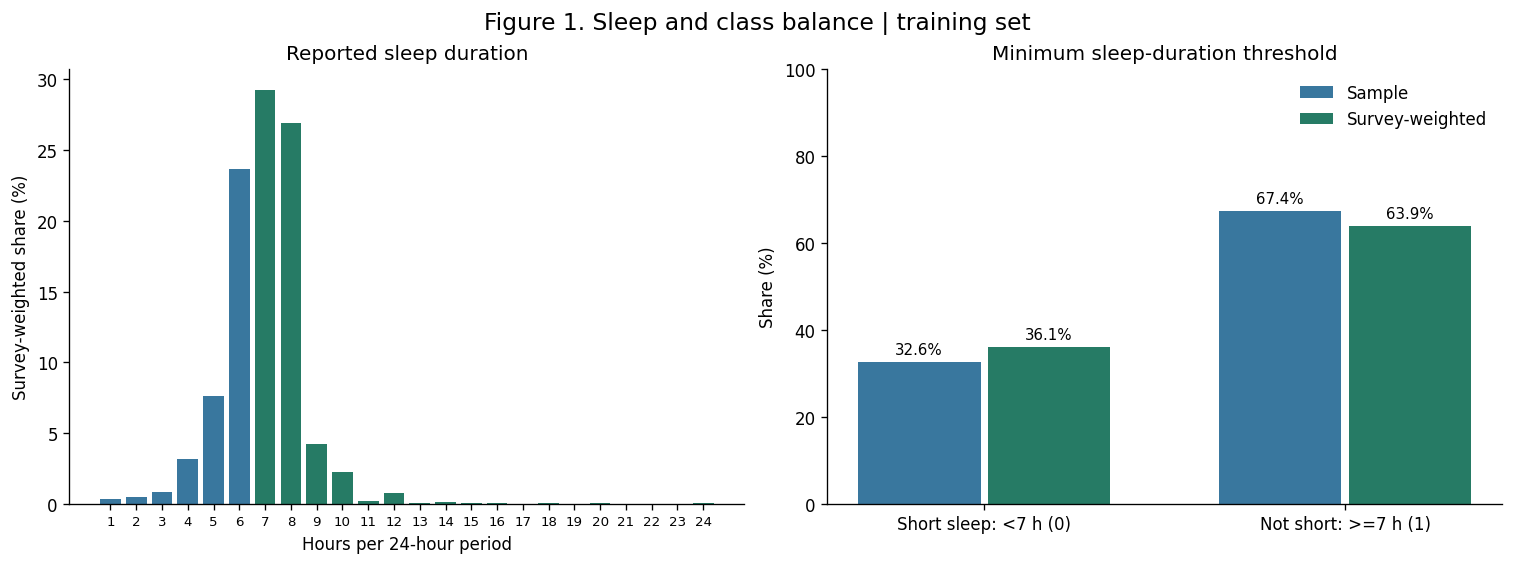

In [9]:
sleep_share = (
    train_data.groupby("sleep_hours")["survey_weight"].sum()
    .reindex(range(1, 25), fill_value=0)
    / train_data["survey_weight"].sum() * 100
)
outcome_summary = pd.DataFrame({
    "sample_percent": train_data["enough_sleep"].value_counts(normalize=True),
    "weighted_percent": (
        train_data.groupby("enough_sleep")["survey_weight"].sum()
        / train_data["survey_weight"].sum()
    ),
}).reindex([0, 1]) * 100
outcome_summary.index = ["Short sleep: <7 h (0)", "Not short: >=7 h (1)"]
display(outcome_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), layout="constrained")
axes[0].bar(sleep_share.index, sleep_share,
            color=[GREEN if h >= 7 else BLUE for h in sleep_share.index])
axes[0].set(title="Reported sleep duration", xlabel="Hours per 24-hour period",
            ylabel="Survey-weighted share (%)", xticks=range(1, 25))
axes[0].tick_params(axis="x", labelsize=8)
positions = np.arange(2)
for offset, column, label, color in [
    (-0.18, "sample_percent", "Sample", BLUE),
    (0.18, "weighted_percent", "Survey-weighted", GREEN),
]:
    bars = axes[1].bar(positions + offset, outcome_summary[column],
                       width=0.34, label=label, color=color)
    axes[1].bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
axes[1].set(title="Minimum sleep-duration threshold", ylabel="Share (%)",
            xticks=positions, xticklabels=outcome_summary.index, ylim=(0, 100))
axes[1].legend(frameon=False)
fig.suptitle("Figure 1. Sleep and class balance | training set", fontsize=14)
plt.show()
plt.close(fig)


**Finding:** The at-least-7-hour class accounts for **67.38%** of the training
sample and **63.94%** after survey weighting. The two classes are unequal,
but both are well represented. The valid upper tail includes **928**
respondents reporting more than 12 hours.

**Implication:** Retain valid unusual durations rather than deleting them
as automatic outliers. Compare models with a majority-class baseline and
imbalance-aware metrics; accuracy alone could be misleading. The shaded
at-least-7-hour range illustrates the published short-sleep threshold, not
an EDA-selected cutoff. Long-sleep respondents meet that minimum but are
not thereby classified as medically healthy. sleep_hours must be excluded
from model inputs to avoid leakage.

### 7.2 Unknown responses

Show how much information is unavailable in each training-set input.


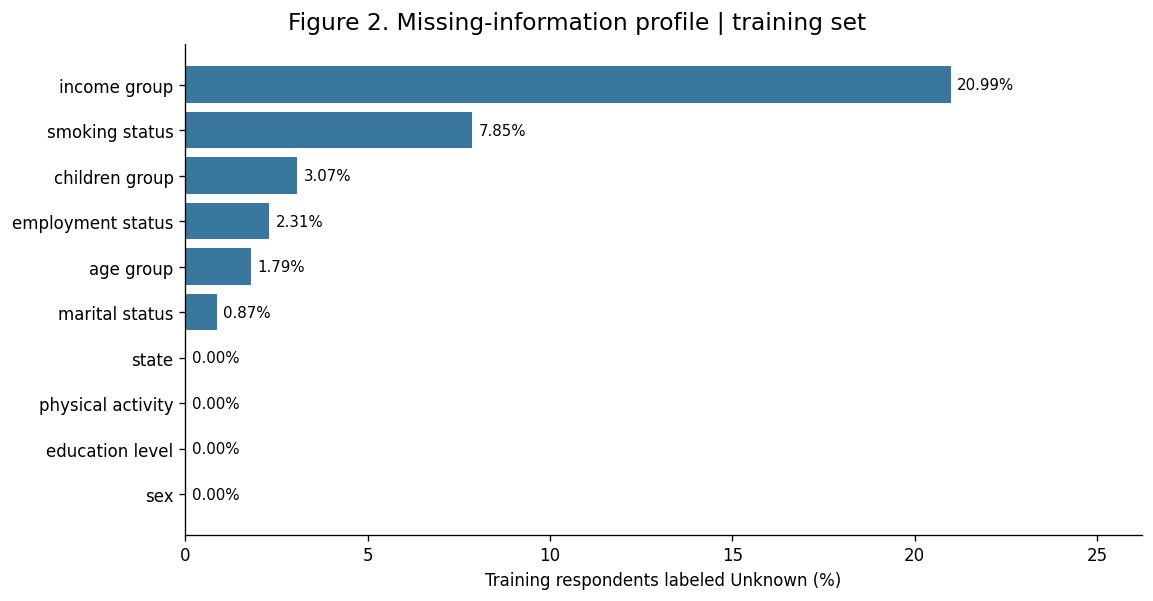

In [10]:
unknown_rates = variable_summary.set_index("column")["unknown_percent"].sort_values()
fig, ax = plt.subplots(figsize=(9.5, 4.9), layout="constrained")
bars = ax.barh(unknown_rates.index.str.replace("_", " "), unknown_rates,
               color=BLUE)
ax.bar_label(bars, fmt="%.2f%%", padding=4, fontsize=9)
ax.set(xlabel="Training respondents labeled Unknown (%)",
       xlim=(0, max(unknown_rates.max() * 1.25, 1)))
fig.suptitle("Figure 2. Missing-information profile | training set", fontsize=14)
plt.show()
plt.close(fig)


**Finding:** After the limited removal in Section 4, training-set income has
**20.99% Unknown**, followed by smoking status at **7.85%**. The full cleaned
dataset has similar rates (21.02% and 7.84%). Education and physical activity
now have zero Unknown because those incomplete records were removed.

**Implication:** Remove only the low-missingness education/activity records
(3,005 rows, 0.70% of the eligible sample). Keep explicit Unknown categories
in the other inputs instead of discarding every incomplete record or
guessing income/smoking values. This does not fix all missing-data bias. The modeling team should
compare key conclusions with a complete-case sensitivity analysis.

### 7.3 Who is represented in the data?

Plot sample counts, with readable age/income/employment labels. Counts show
representation in the survey sample, not the population distribution.


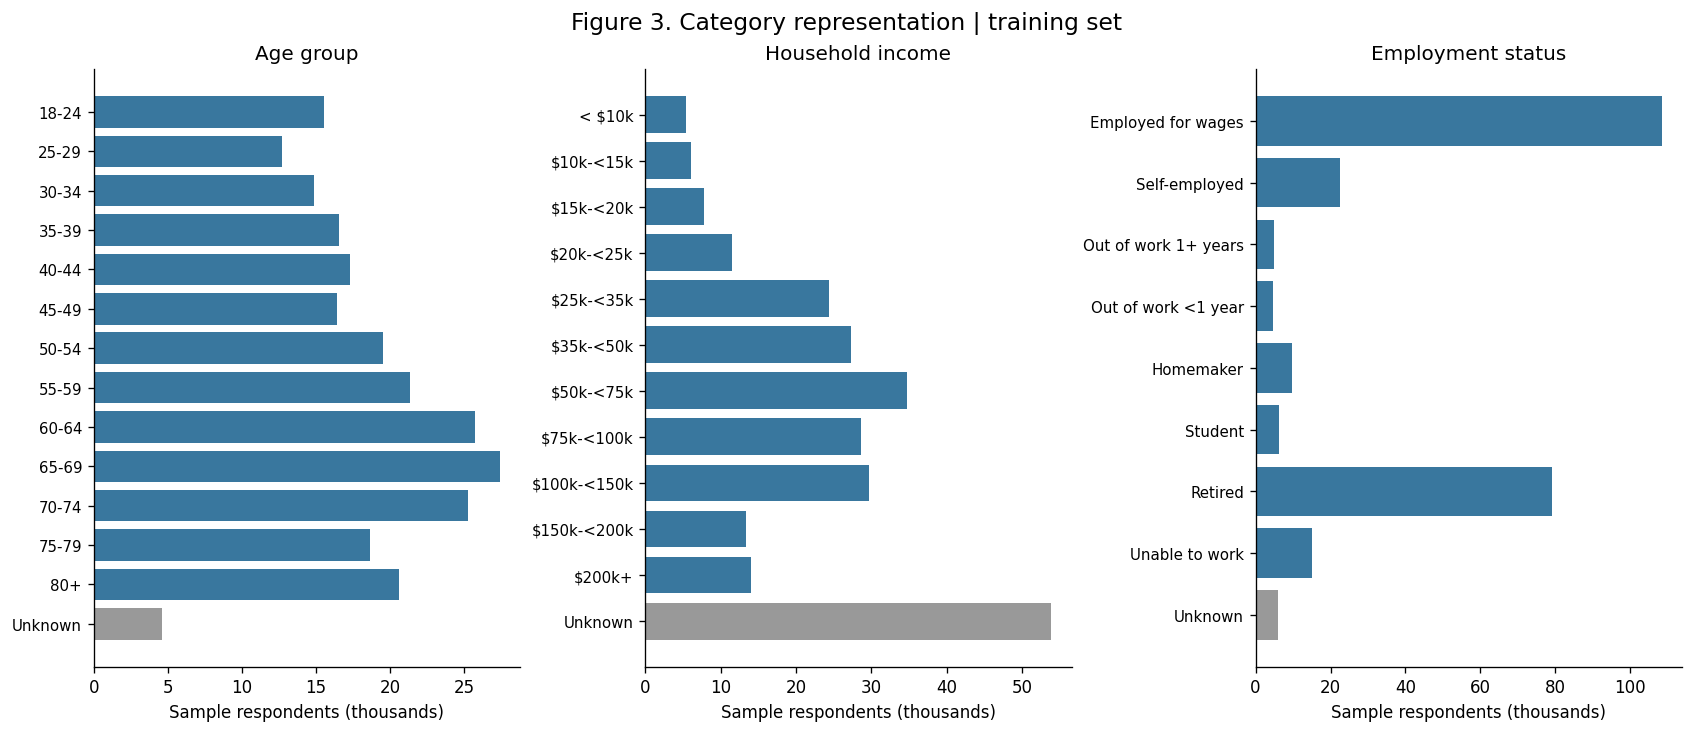

In [11]:
# Readable labels for plots only: exported data keep their existing values.
plot_labels = {
    "age_group": dict(zip([str(i) for i in range(1, 14)], [
        "18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
        "55-59", "60-64", "65-69", "70-74", "75-79", "80+",
    ])),
    "income_group": dict(zip([str(i) for i in range(1, 12)], [
        "< $10k", "$10k-<15k", "$15k-<20k", "$20k-<25k", "$25k-<35k",
        "$35k-<50k", "$50k-<75k", "$75k-<100k", "$100k-<150k",
        "$150k-<200k", "$200k+",
    ])),
    "employment_status": dict(zip([str(i) for i in range(1, 9)], [
        "Employed for wages", "Self-employed", "Out of work 1+ years",
        "Out of work <1 year", "Homemaker", "Student", "Retired", "Unable to work",
    ])),
    "physical_activity": {"1": "Any activity", "2": "No activity"},
}
plot_titles = {
    "age_group": "Age group", "income_group": "Household income",
    "employment_status": "Employment status", "physical_activity": "Physical activity",
}
for mapping in plot_labels.values():
    mapping["Unknown"] = "Unknown"

fig, axes = plt.subplots(1, 3, figsize=(14, 6), layout="constrained")
for ax, column in zip(axes, ["age_group", "income_group", "employment_status"]):
    order = list(plot_labels[column])
    counts = train_data[column].value_counts().reindex(order, fill_value=0)
    ax.barh([plot_labels[column][x] for x in order], counts / 1000,
            color=[GRAY if x == "Unknown" else BLUE for x in order])
    ax.invert_yaxis()
    ax.set(title=plot_titles[column], xlabel="Sample respondents (thousands)")
    ax.tick_params(axis="y", labelsize=9)
fig.suptitle("Figure 3. Category representation | training set", fontsize=14)
plt.show()
plt.close(fig)


**Finding:** Employment groups have very different sample sizes: **108,361**
respondents are employed for wages and **79,207** are retired, compared with
**4,604** out of work for less than a year. Income also has a large Unknown
group. Age/income categories retain their original order and intervals.

**Implication:** Compare within-group percentages rather than raw numbers
of respondents meeting the duration threshold. Large groups would otherwise dominate the
comparison. Keep age and income categorical; converting their codes into
precise ages or incomes would invent measurements that were not collected.

### 7.4 How does the sleep label vary across groups?

For each category, compute **sum(weight * enough_sleep) / sum(weight)**.
These are unadjusted weighted descriptive percentages, including Unknown.
The dashed line is the overall weighted training percentage. We also display
group counts and unweighted percentages for context.


Age group


,respondents,sample_percent,weighted_percent
18-24,15520,67.48,66.49
25-29,12691,64.66,63.32
30-34,14875,61.14,59.38
35-39,16556,60.18,57.73
40-44,17299,61.33,58.53
45-49,16441,61.69,60.28
50-54,19511,61.37,59.76
55-59,21361,63.70,61.45
60-64,25760,66.82,64.02
65-69,27416,71.25,69.77


Household income


,respondents,sample_percent,weighted_percent
< $10k,5472,56.96,58.10
$10k-<15k,6029,57.69,56.07
$15k-<20k,7818,60.55,59.53
$20k-<25k,11480,61.32,59.55
$25k-<35k,24394,63.83,61.14
$35k-<50k,27252,66.36,62.61
$50k-<75k,34743,67.49,62.68
$75k-<100k,28588,69.41,64.48
$100k-<150k,29650,69.97,65.31
$150k-<200k,13335,71.25,68.15


Employment status


,respondents,sample_percent,weighted_percent
Employed for wages,108361,64.18,61.30
Self-employed,22426,68.67,65.37
Out of work 1+ years,4899,59.24,58.98
Out of work <1 year,4604,61.45,60.07
Homemaker,9731,69.24,68.25
Student,6364,69.08,68.91
Retired,79207,75.23,72.61
Unable to work,15087,50.74,50.93
Unknown,5926,64.77,62.53


Physical activity


,respondents,sample_percent,weighted_percent
Any activity,196260,69.13,65.48
No activity,60345,61.67,58.95


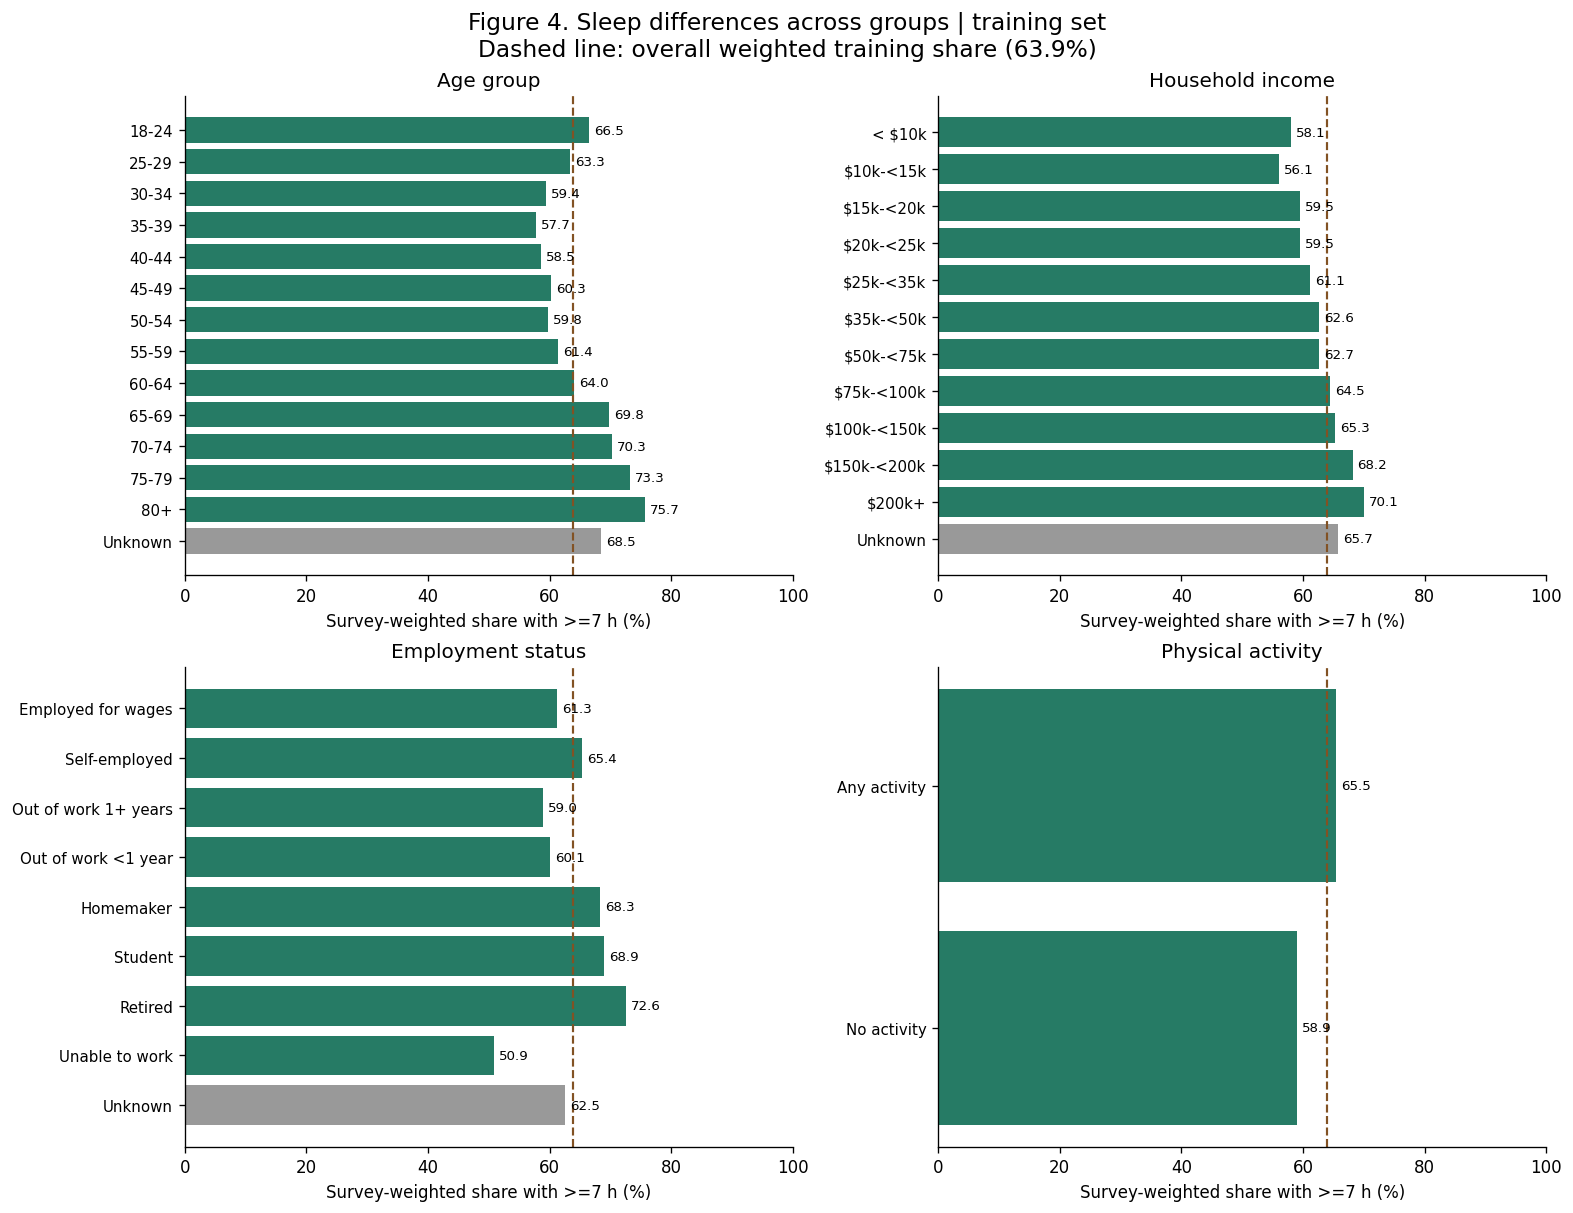

In [12]:
group_summaries = {}
weighted_outcome = train_data.assign(
    weighted_enough=train_data["survey_weight"] * train_data["enough_sleep"]
)
overall_rate = weighted_outcome["weighted_enough"].sum() / train_data["survey_weight"].sum() * 100
for column in plot_labels:
    table = weighted_outcome.groupby(column).agg(
        respondents=("enough_sleep", "size"),
        sample_percent=("enough_sleep", "mean"),
        total_weight=("survey_weight", "sum"),
        enough_weight=("weighted_enough", "sum"),
    ).reindex([level for level in plot_labels[column]
               if level in set(train_data[column])])
    table["sample_percent"] *= 100
    table["weighted_percent"] = table["enough_weight"] / table["total_weight"] * 100
    table.index = [plot_labels[column][x] for x in table.index]
    group_summaries[column] = table
    print(plot_titles[column])
    display(table[["respondents", "sample_percent", "weighted_percent"]].round(2))

fig, axes = plt.subplots(2, 2, figsize=(13, 10), layout="constrained")
for ax, column in zip(axes.flat, plot_labels):
    table = group_summaries[column]
    colors = [GRAY if x == "Unknown" else GREEN for x in table.index]
    bars = ax.barh(table.index, table["weighted_percent"], color=colors)
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8)
    ax.axvline(overall_rate, color="#825224", linestyle="--", linewidth=1.3)
    ax.invert_yaxis()
    ax.set(title=plot_titles[column], xlabel="Survey-weighted share with >=7 h (%)", xlim=(0, 100))
    ax.tick_params(axis="y", labelsize=9)
fig.suptitle("Figure 4. Sleep differences across groups | training set\n"
             f"Dashed line: overall weighted training share ({overall_rate:.1f}%)", fontsize=14)
plt.show()
plt.close(fig)


**Findings:**
- Reported sleep of at least 7 hours varies non-monotonically with age: **57.73%**
  among ages 35-39, compared with **75.74%** among ages 80+.
- Income categories show an overall upward pattern, with exceptions:
  **58.10%** below $10,000 versus **70.08%** at $200,000 or more.
- The weighted share is **50.93%** among respondents unable to work and
  **72.61%** among retired respondents.
- Respondents reporting leisure-time activity have a **65.48%** share,
  compared with **58.95%** among those reporting no activity.

**Implications:** These patterns motivate retaining demographic,
socioeconomic, and lifestyle inputs and comparing them jointly in a
multivariable model. The non-monotonic age pattern supports categorical
encoding rather than treating age-group codes as a linear measurement.
Employment differences may partly reflect age, health, and other factors.
These charts do not establish causation, statistical significance, or how
accurately a model will predict an individual's sleep label.

### 7.5 Do the categorical inputs contain redundant information?

Visualize the training-set Cramer's V values calculated in Section 6.
Unknown is included as a category. The diagonal is masked because each
variable is perfectly associated with itself.


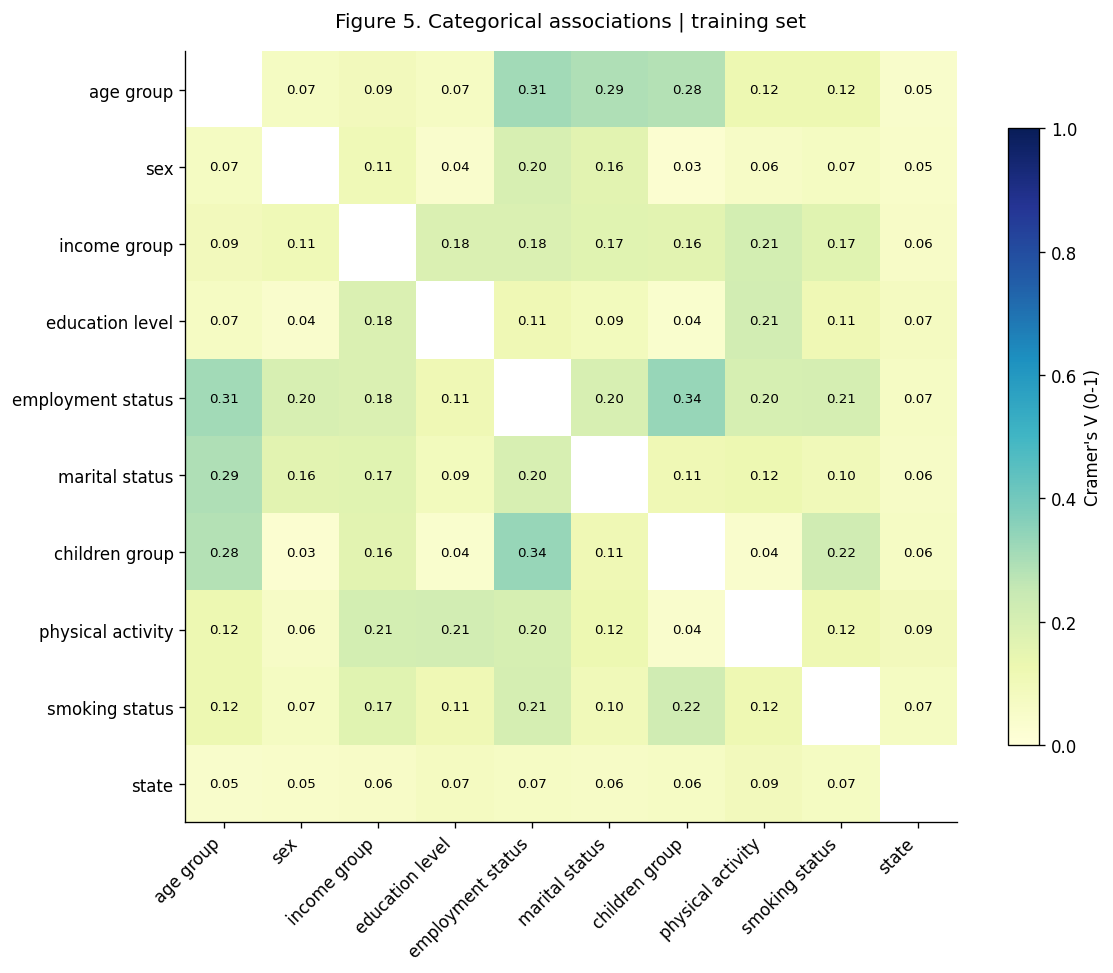

In [13]:
association_matrix = pd.DataFrame(
    np.nan, index=category_columns, columns=category_columns
)
for row in association_summary.itertuples(index=False):
    association_matrix.loc[row.first, row.second] = row.cramers_v
    association_matrix.loc[row.second, row.first] = row.cramers_v

fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
image = ax.imshow(association_matrix.to_numpy(), vmin=0, vmax=1, cmap="YlGnBu")
short_labels = [c.replace("_", " ") for c in category_columns]
ax.set_xticks(range(len(short_labels)), labels=short_labels, rotation=45, ha="right")
ax.set_yticks(range(len(short_labels)), labels=short_labels)
for i in range(len(category_columns)):
    for j in range(len(category_columns)):
        value = association_matrix.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, shrink=0.8, label="Cramer's V (0-1)")
ax.set_title("Figure 5. Categorical associations | training set", pad=15)
plt.show()
plt.close(fig)


**Finding:** The largest pairwise association is approximately **0.336**
between employment status and household children group. These checks do
not identify near-perfect duplication among the ten inputs.

**Implication:** Retain the ten distinct characteristics for the planned
model comparison. Cramer's V is appropriate for category labels; ordinary
Pearson correlation on arbitrary integer codes is not. This diagnostic does
not rule out every form of multicollinearity or replace hypothesis testing.

### EDA findings informing the next steps

| Evidence | Decision or next step |
|---|---|
| Valid but unusual sleep durations | Retain them; exclude invalid CDC responses instead. |
| Low education/activity Unknown rates; substantial income Unknown | Drop 3,005 education/activity-incomplete rows (0.70%); retain other Unknown categories and plan a complete-case sensitivity check. |
| Unequal category counts and survey weights | Report group denominators; use weighted percentages for group descriptions. |
| Age/income/employment/activity differences | Retain relevant categorical inputs for multivariable modeling; interpret associations cautiously. |
| Unequal outcome classes | Compare with a majority-class baseline and imbalance-aware metrics. |
| No near-perfect pairwise categorical association | Retain all ten inputs at this stage. |

The five figures are generated by the Python plotting cells and displayed
directly in this notebook. No separate image files are required.
For the final presentation, select the **3-5** figures that best explain the
data and findings. The notebook retains the cleaning logic and supporting
evidence. This section completes descriptive EDA, not the baseline model
or simulation-based hypothesis tests assigned to the modeling/testing team.
